In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scanpy as sc
import sys

sys.path.append("../../utils/HLCA")
import data_cleanup

In [3]:
%load_ext lab_black

In [4]:
path_hlca_full = "/ictstr01/groups/ml01/projects/2024_hlca_v2_raphael.kfurirubens/hlca_v1/hlca_v1_full.h5ad"

In [5]:
adata_full = sc.read_h5ad(path_hlca_full, backed="r")

subset to pericytes/smooth muscle:

In [6]:
mask = (
    (adata_full.obs.ann_level_2 == "Smooth muscle")
    | (adata_full.obs.ann_level_4 == "Pericytes")
    | (adata_full.obs.transf_ann_level_2_label == "Smooth muscle")
    | (adata_full.obs.transf_ann_level_4_label == "Pericytes")
)

In [7]:
adata = adata_full[mask, :].to_memory()

set gene names as var row name (instead of gene id):

In [8]:
adata.var["ensembl_id"] = adata.var.index
adata.var.index = adata.var.feature_name

remove raw (not needed):

In [9]:
del adata.raw

merge HLCA core manual annotation with HLCA extension transfered labels:

In [10]:
for lev in range(1, 6):
    adata.obs[f"ann_level_{lev}_merged"] = adata.obs[f"ann_level_{lev}"].tolist()
    adata.obs.loc[
        adata.obs.core_or_extension == "extension", f"ann_level_{lev}_merged"
    ] = adata.obs.loc[
        adata.obs.core_or_extension == "extension", f"transf_ann_level_{lev}_label"
    ]
    adata.obs[f"ann_level_{lev}_clean"] = data_cleanup.clean_up_df_column(
        adata.obs, f"ann_level_{lev}_merged", 500
    )

create obs column that is a combination of ann and study, then create obs column that is a combination of ann, study and lung condition:

In [21]:
for lev in [4]:
    adata.obs[f"ann_level_{lev}_study"] = [
        f"{ct}_{study}"
        for ct, study in zip(adata.obs[f"ann_level_{lev}_clean"], adata.obs.study)
    ]
    adata.obs[f"ann_level_{lev}_study"] = data_cleanup.clean_up_df_column(
        adata.obs, f"ann_level_{lev}_study", 50
    )
    adata.obs[f"ann_level_{lev}_study_lung_condition"] = [
        f"{ct}_{study}"
        for ct, study in zip(
            adata.obs[f"ann_level_{lev}_study"], adata.obs.lung_condition
        )
    ]
    adata.obs[
        f"ann_level_{lev}_study_lung_condition"
    ] = data_cleanup.clean_up_df_column(
        adata.obs, f"ann_level_{lev}_study_lung_condition", 10
    )

look for state observed in Sheppard_2020 IPF

In [12]:
markers_Sheppard_analysis = {
    "Smooth muscle": ["MYH11", "TINAGL1", "PLN"],
    # "Pericytes general": ["HIGD1B", "PTN"],
    "up in IPF SM": [
        "IGFBP2",
        "RGS5",
        "STEAP4",
        "FAM162B",
        "TCIM",
        "CCL21",
        "ARHGAP15",
        "CD36",
        "PTGER1",
    ],
}

In [13]:
adata.obs.loc[
    (adata.obs.study == "Banovich_Kropski_2020")
    & (adata.obs.lung_condition == "Healthy"),
    "ann_level_3_merged",
].value_counts()

None                            536
Fibroblasts                     478
SM activated stress response     37
Smooth muscle FAM83D+            10
Name: ann_level_3_merged, dtype: int64

In [14]:
adata.obs.loc[
    (adata.obs.study == "Misharin_Budinger_2018")
    & (adata.obs.lung_condition == "Healthy"),
    "ann_level_2_merged",
].value_counts()

Smooth muscle         31
Fibroblast lineage     1
Name: ann_level_2_merged, dtype: int64

In [15]:
studies_to_plot = [
    "Sheppard_2020",
    "Banovich_Kropski_2020",
    "Kaminski_2020",
    "Misharin_Budinger_2018",
    # "Schiller_2020", Has really weird expression patterns, already observed this in the HLCA analysis, will leave out
    # "Lafyatis_2019", # only SS ILD
    # "Budinger_2020",  # Does not have healthy SM/pericytes, like many studies...
]

plot all at once:

In [16]:
adata.obs["study_cond"] = [
    f"{study}, {cond}" for cond, study in zip(adata.obs.lung_condition, adata.obs.study)
]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


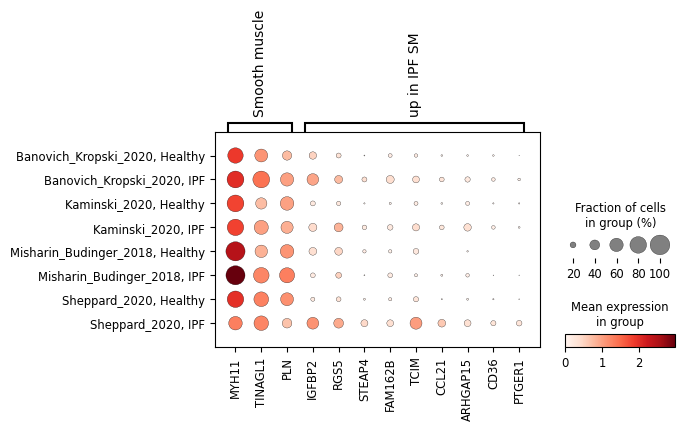

In [17]:
sc.pl.dotplot(
    adata[
        (
            adata.obs.ann_level_2_merged.isin(
                [
                    "Smooth muscle",
                ]
            )
        )
        & (
            adata.obs.study.isin(studies_to_plot)
            & (
                adata.obs.lung_condition.isin(
                    [
                        "Healthy",
                        "Healthy (tumor adjacent)",
                        "IPF",
                    ]
                )
            )
        ),
        :,
    ],
    var_names=markers_Sheppard_analysis,
    groupby="study_cond",
)

or one at a time. This is better as the counts are not batch-corrected, and therefore comparing between studies is easier.

In [18]:
adata.obs.ann_level_3_merged.value_counts()[:6]

2_Smooth muscle                 26215
Fibroblasts                     16164
SM activated stress response     4983
None                             2996
Smooth muscle FAM83D+            1036
Myofibroblasts                     79
Name: ann_level_3_merged, dtype: int64

In [19]:
adata.obs.ann_level_4_merged.value_counts()[:6]

2_Smooth muscle                   26308
Pericytes                         16065
3_SM activated stress response     4433
None                               3887
3_Smooth muscle FAM83D+             702
3_Myofibroblasts                     79
Name: ann_level_4_merged, dtype: int64

Sheppard_2020
Number of smooth muscle cells per group:
IPF                                  11616
Systemic sclerosis-associated ILD     4856
Healthy                               2738
Name: lung_condition, dtype: int64


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


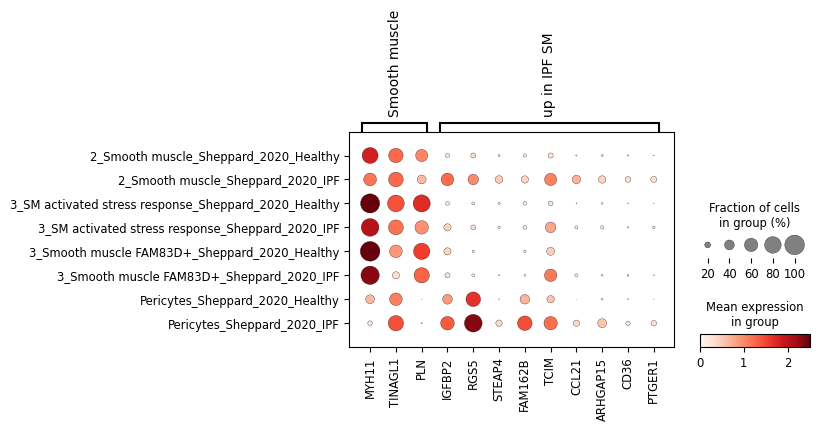

Banovich_Kropski_2020
Number of smooth muscle cells per group:
Healthy        583
IPF            488
NSIP           285
HP              62
ILD             23
Sarcoidosis      9
Name: lung_condition, dtype: int64


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


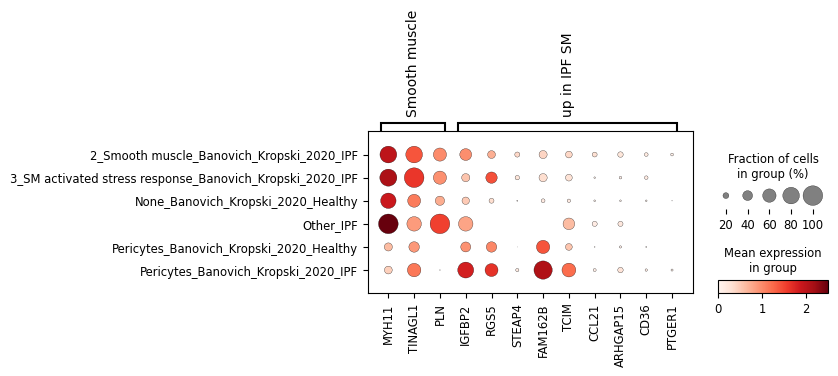

Kaminski_2020
Number of smooth muscle cells per group:
IPF        678
COPD        83
Healthy     75
Name: lung_condition, dtype: int64


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


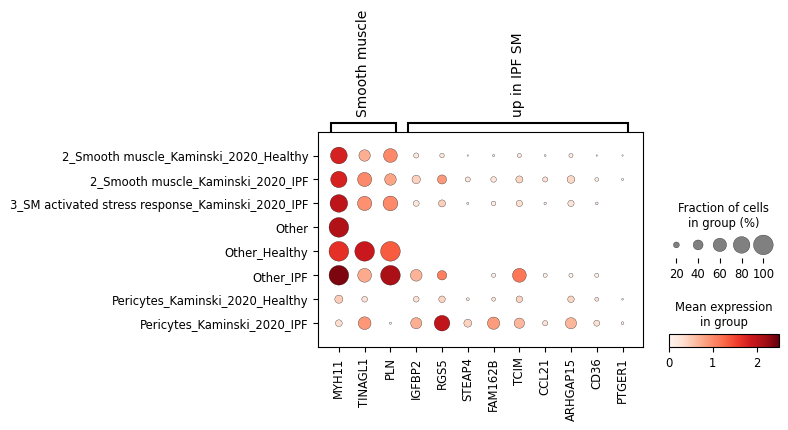

Misharin_Budinger_2018
Number of smooth muscle cells per group:
IPF                                  106
Healthy                               31
Systemic sclerosis-associated ILD     11
Myositis-associated ILD                7
HP                                     5
Name: lung_condition, dtype: int64


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


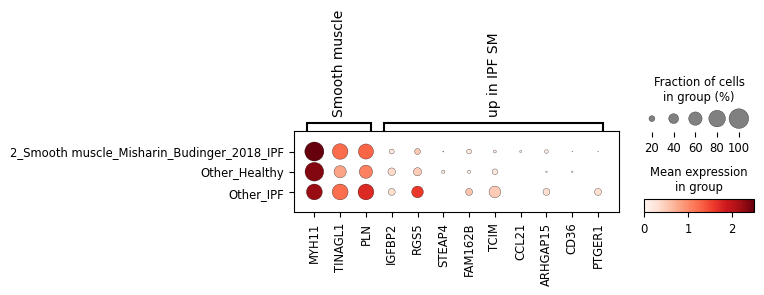

In [22]:
for study in studies_to_plot:
    print(study)
    print("Number of smooth muscle cells per group:")
    cell_count_per_group = adata.obs.loc[
        (adata.obs.ann_level_2_merged.isin(["Smooth muscle"]))
        & (adata.obs.study == study),
        "lung_condition",
    ].value_counts()
    cell_count_per_group = cell_count_per_group[cell_count_per_group > 0]
    print(cell_count_per_group)
    sc.pl.dotplot(
        adata[
            (
                adata.obs.ann_level_4_merged.isin(  # or ann level 4?
                    [
                        "2_Smooth muscle",
                        "Pericytes",
                        "3_Smooth muscle FAM83D+",
                        "3_SM activated stress response",
                        "None",
                    ]
                )
            )
            & (
                adata.obs.study.isin([study])
                & (
                    adata.obs.lung_condition.isin(
                        [
                            "Healthy",
                            "Healthy (tumor adjacent)",
                            "IPF",
                        ]
                    )
                )
            ),
            :,
        ],
        var_names=markers_Sheppard_analysis,
        groupby="ann_level_4_study_lung_condition",
        dot_max=1,
        vmax=2.5,
    )

In [ ]:
# pd.crosstab(adata.obs.study, adata.obs.lung_condition)